In [ ]:
from data_process import *
from mcar.simulate import *
from graphOUedge import GraphOUEdge

def pred_robust(seed: int, p: float, gamma: float, num_node: int, scale: float, T: int, forecast_step: int):
    dir = 'p_' + str(p) + '_gamma_' + str(gamma)
    TICKERS = [str(i) for i in range (num_node)]
    G = nx.erdos_renyi_graph(num_node, p, seed=seed)
    G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))
    A = nx.to_numpy_array(G)

    adj_sim = adj_to_line_graph(A, TICKERS)
    adj_L_sim = adjacency_matrices(adj_sim[0], 1)
    W_C_sim = edge_weight(adj_L_sim)
    X_sim = GraphOUEdge([1], len(adj_sim[1]), 1, adj_L_sim, W_C_sim, gamma, dir, scale=scale, T=T)
    X_sim.alpha_set(np.array([[5]+[1 for _ in range(len(adj_sim[1]) - 1)]]))
    X_sim.beta_set([[2]])
    X_sim.Q_matrix()
    data_sim = X_sim.simulate('CP', 1000, seed=1000, rate=1)

    edges = list(G.edges())
    G_without_first = G.copy()
    first_edge = edges[0]
    G_without_first.remove_edge(*first_edge)
    A_without_first = nx.to_numpy_array(G_without_first, nodelist=TICKERS)

    G_without_last = G.copy()
    last_edge = edges[-1]
    G_without_last.remove_edge(*last_edge)
    A_without_last = nx.to_numpy_array(G_without_last, nodelist=TICKERS)

    model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='correct', scenario=dir)
    model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_first, TICKERS), forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='missing_5', scenario=dir)
    model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_last, TICKERS), forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='missing_1', scenario=dir)

    boxplot_(data_sim, dir)

In [ ]:
pred_robust(123, 0.15, 1.25, 20, 1, 3, 1)

In [ ]:
#section 4.1 larger graph 20 vertex 34 edges gamma = 1.01, T = 2,4,8, 3 regimes, 2 lags, get parameter estimation error averaged
#section 4.2-4.3 larger graph 20 vertex 34 edges gamma = 1.01, T = 3, 1 regimes, 1 lag, sigma = 1, 10
#section 4.2-4.3 10-edge graph with different gamma and grid only grOU model, jump detection, true/false postiive rate

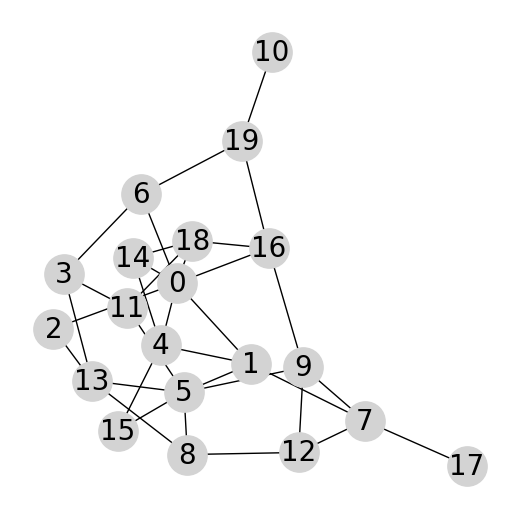

1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200


In [1]:
from data_process import *
from mcar.simulate import *
from graphOUedge import GraphOUEdge

num_node = 20
p = 0.15
seed = 123
gamma = 1.01
scale = 1

TICKERS = [str(i) for i in range (num_node)]
G = nx.erdos_renyi_graph(num_node, p, seed=seed)
G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))
pos = nx.spring_layout(G, seed=1)

plt.figure(figsize=(5, 5))
nx.draw(G, pos, with_labels=True, node_size=800, node_color='lightgrey', font_size=20)
plt.show()

A = nx.to_numpy_array(G)
adj_sim = adj_to_line_graph(A, TICKERS)
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1,1], len(adj_sim[1]), 1, adj_L_sim, W_C_sim, gamma, '')
X_sim.alpha_set(np.array([[2 for _ in range(len(adj_sim[1]))], [1 for _ in range(len(adj_sim[1]))]]))
X_sim.beta_set([[1],[0.5]])
X_sim.Q_matrix()


for regime in ['Gamma']:
    estimate = []
    for j in range(200):
        print(str(j + 1))
        sim = X_sim.simulate(regime, 5, seed=134 + 100 * j, rate=1)
        P = np.linspace(0, 8, 8 ** 7 + 1)
        args = [(P, [1,1], len(adj_sim[1]), 1, sim[i], adj_L_sim, W_C_sim, gamma) for i in range(5)]
        with Pool(os.cpu_count()) as pool:
            results = pool.map(process_one_sim, args)
        estimate.extend(results)

    with open('./data/LOBSTERdata/output/sim/large_estimate_' + regime + '.npy', 'wb') as f:
        np.save(f, estimate)

In [ ]:
for regime in ['BM', 'CP', 'Gamma']:
    with open('./data/LOBSTERdata/output/sim/large_estimate_' + regime + '.npy', 'rb') as f:
        estimate = np.load(f)

    fig, axes = plt.subplots(3, 3, figsize=(13, 12), squeeze=False)
    for log2t in range(1, 4):
        for n in range(2):
            for m in range(1):
                ax = axes[n, log2t - 1]
                x = estimate[:, log2t - 1, n * 35 + m]
                y = estimate[:, log2t - 1, n * 35 + m + 1]
                mask = (abs(x) < 100) & (abs(y) < 100)
                x_clean = x[mask]
                y_clean = y[mask]

                k = scipy.stats.gaussian_kde(np.vstack([x_clean, y_clean]))
                xi, yi = np.mgrid[-1:7:100 * 1j, -1:7:100 * 1j]
                zi = k(np.vstack([xi.flatten(), yi.flatten()]))

                ax.contourf(xi, yi, zi.reshape(xi.shape), cmap='Blues_r')

                ax.set_xticks([-1, 0, 1, 2, 3, 4, 5, 6, 7])
                ax.set_yticks([-1, 0, 1, 2, 3, 4, 5, 6, 7])
                ax.tick_params(axis='both', labelsize=13)
                ax.set_xlabel(r'$\alpha_{%i,%i}$' % (2 * m + 1, n + 1), fontsize=16)
                ax.set_ylabel(r'$\alpha_{%i,%i}$' % (2 * m + 2, n + 1), fontsize=16)
                ax.plot(X_sim.Q_get()[n][2 * m][2 * m], X_sim.Q_get()[n][2 * m + 1][2 * m + 1], color='red', marker='.', markersize=15)
                ax.set_box_aspect(1)

                if n == 0 and m == 0:
                    ax.set_title(r'$t = %i$' % 2 ** log2t, fontsize=20)

        ax = axes[2, log2t - 1]
        x = estimate[:, log2t - 1, 34]
        y = estimate[:, log2t - 1, 69]
        mask = (abs(x) < 100) & (abs(y) < 100)
        x_clean = x[mask]
        y_clean = y[mask]

        k = scipy.stats.gaussian_kde(np.vstack([x_clean, y_clean]))
        xi, yi = np.mgrid[-3:6:100 * 1j, -3:6:100 * 1j]
        zi = k(np.vstack([xi.flatten(), yi.flatten()]))

        ax.contourf(xi, yi, zi.reshape(xi.shape), cmap='Blues_r')

        ax.set_xticks([-3,-2,-1, 0, 1, 2, 3, 4, 5, 6])
        ax.set_yticks([-3,-2,-1, 0, 1, 2, 3, 4, 5, 6])
        ax.tick_params(axis='both', labelsize=13)
        ax.set_xlabel(r'$\beta_{%i}$' % 1, fontsize=16)
        ax.set_ylabel(r'$\beta_{%i}$' % 2, fontsize=16)
        ax.plot(1, 0.5, color='red', marker='.', markersize=15)
        ax.set_box_aspect(1)

    fig.savefig('./data/LOBSTERdata/output/sim/large_estimate_' + regime + '.eps', bbox_inches='tight', format='eps')

In [ ]:
theta_star = np.array([*np.diag(X_sim.Q_get()[0]), 1, *np.diag(X_sim.Q_get()[1]), 0.5])
for regime in ['BM', 'CP', 'Gamma']:
    with open('./data/LOBSTERdata/output/sim/large_estimate_' + regime + '.npy', 'rb') as f:
        theta_hat = np.load(f)
    for t_idx, T in enumerate([2, 4, 8]):
        est = theta_hat[:, t_idx, :]                      # (10, 70)

        # --- per-sample errors (pooling all 70 parameters) ---
        diff = est - theta_star                           # (10, 70)
        l2_error_per_sample = np.linalg.norm(diff, axis=1)
        rel_error_per_sample = l2_error_per_sample / np.linalg.norm(theta_star)

        # --- scalar summaries across samples and parameters ---
        mean_l2_error = l2_error_per_sample.mean()
        sd_l2_error = l2_error_per_sample.std(ddof=1)
        mean_rel_error = rel_error_per_sample.mean()

        overall_rmse = np.sqrt((diff ** 2).mean())
        overall_rel_rmse = overall_rmse / np.sqrt((theta_star ** 2).mean())

        results[t_idx] = dict(
            mean_l2_error=mean_l2_error,
            sd_l2_error=sd_l2_error,
            mean_rel_error=mean_rel_error,
            overall_rmse=overall_rmse,
            overall_rel_rmse=overall_rel_rmse
        )

    # ------------------------------------------------------------------
    # 3. Print convergence tables
    # ------------------------------------------------------------------
    print(f"Regime: ", regime)
    print(f"{'T':>4} | {'mean ||err||_2':>15} | {'sd':>8} | {'mean rel err':>13} | "
          f"{'overall RMSE':>13} | {'overall rel RMSE':>17}")
    for t_idx, T in enumerate([2, 4, 8]):
        r = results[t_idx]
        print(f"{T:>4} | {r['mean_l2_error']:>15.5f} | {r['sd_l2_error']:>8.5f} | "
              f"{r['mean_rel_error']:>13.5f} | {r['overall_rmse']:>13.5f} | {r['overall_rel_rmse']:>17.5f}")
